# Structural Characteristics (Constructed + Constructed)

> **Important: focus on tabular camera-ready output!**

## Pairwise 

1. Node Jaccard Index
   1. _with overview_
3. Path Jaccard Index
   1. _with overview_
4. APTED tree similarity
   1. _with change breakdown_

## Preamble

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 83.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings

In [3]:
from lxml import etree
import apted

In [4]:
import massi.agents.tools as matls

In [5]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [6]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [7]:
import tol_colors as tcls

In [8]:
import itertools as itlx
import json
from pathlib import Path
import re 

In [9]:
from typing import TypedDict, Any

In [10]:
from IPython.display import display, display_markdown

In [11]:
from pprint import pprint

In [12]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [13]:
pd.set_option('display.max_colwidth', None)

### Utilities

In [14]:
def fmt_result_group_title_multiline(t: str)->str:
    return "\nx\n".join(t.split("~"))

def fmt_result_group_title_oneline(t: str)->str:
    return " x ".join(t.split("~"))

In [15]:
from warnings import warn

class OutcomeContainer[T](TypedDict):
    value: T | None
    error: str | None

def do_or_error(func) -> OutcomeContainer[Any]: 
    def wrapper(*args, **kwargs):
        try:
            return {"value": func(*args, **kwargs), "error": None}
        except Exception as e:
            return {"error": f"{type(e)}: {str(e)}", "value": None}
    return wrapper

def do_on_value(func):
    def wrapper(c: OutcomeContainer[Any], *args, **kwargs):
        if c["value"] is not None:
            return func(c["value"], *args, **kwargs)
        else:
            return c
    return wrapper

In [16]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [17]:
def ok_results(df):
    return df[df["success"]]

### Constructs

In [18]:
@do_or_error
def parse_xml_file(path: str | Path):
    return etree.parse(path)

@do_or_error
def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

@do_on_value
def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

In [19]:
@do_or_error
def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

In [20]:
@do_on_value
@do_or_error
def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

@do_on_value
@do_or_error
def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [21]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: str # <-- json.dumps(attributes)
    attributes_count: int # <-- |attributes.keys()|
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <-- |_nodes|
    size_with_attributes: int # <-- SUM(n.attributes_count for n in _nodes)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    public_data = {k:v for k,v in d.items() if not str(k).startswith("_")}
    return public_data

In [22]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

In [23]:
@do_on_value
@do_or_error
def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": json.dumps(dict(node.attrib.items())),
            "attributes_count": len(node.attrib.keys()),
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes_info = list(map(_get_node_info, root.iter()))
    return {
        "size": len(nodes_info), 
        "size_with_attributes": len(nodes_info) + sum(n["attributes_count"] for n in nodes_info),
        "_nodes": nodes_info
    }

## Data collection

In [24]:
gbif_cases = pd.read_csv("../../runtime/full_gbif_cases.csv")
experiment_results = pd.read_csv("../../runtime/experiment_cross_scenarios_cases.log.csv")

In [25]:
dwc_data_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "data-focus")]
dwc_author_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "author-focus")]

eml_data_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "data-focus")]
eml_author_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "author-focus")]

In [26]:
result_groups = {
    "DwC-T~Data": dwc_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
    "DwC-T~Author": dwc_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Data": eml_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Author": eml_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
}
result_group_2_ground_truth = {
    "DwC-T~Data": "ground_truth_metadata_dwc",
    "DwC-T~Author": "ground_truth_metadata_dwc", 
    "EML~Data": "ground_truth_metadata_eml", 
    "EML~Author": "ground_truth_metadata_eml",
}
cross_group_key_pairs = {
    ("DwC-T~Data", "DwC-T~Author"),
    ("EML~Data", "EML~Author"),
}

for g, rs in result_groups.items():
    display(f"> --- Result Group: `{g}` ---")
    display(rs.describe())

'> --- Result Group: `DwC-T~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,164.296089,0.0,0.0,153.513966,2.0,89.000000,46.359027,1.778160e+09
std,99.617169,0.0,0.0,99.156009,0.0,51.816986,77.392903,1.187505e+04
min,0.000000,0.0,0.0,0.000000,2.0,0.000000,12.870421,1.778149e+09
25%,84.500000,0.0,0.0,68.000000,2.0,44.500000,22.477583,1.778155e+09
50%,159.000000,0.0,0.0,151.000000,2.0,89.000000,30.010789,1.778159e+09
75%,263.500000,0.0,0.0,233.500000,2.0,133.500000,43.288641,1.778165e+09
max,444.000000,0.0,0.0,336.000000,2.0,178.000000,765.560462,1.778260e+09


'> --- Result Group: `DwC-T~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,194.670391,4.0,4.0,153.513966,2.0,89.000000,42.249969,1.778161e+09
std,109.385350,0.0,0.0,99.156009,0.0,51.816986,54.813842,1.193789e+04
min,10.000000,4.0,4.0,0.000000,2.0,0.000000,14.248861,1.778150e+09
25%,114.500000,4.0,4.0,68.000000,2.0,44.500000,24.495313,1.778156e+09
50%,189.000000,4.0,4.0,151.000000,2.0,89.000000,29.604584,1.778160e+09
75%,310.500000,4.0,4.0,233.500000,2.0,133.500000,42.310426,1.778167e+09
max,445.000000,4.0,4.0,336.000000,2.0,178.000000,478.510206,1.778260e+09


'> --- Result Group: `EML~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,515.670391,8.0,8.0,153.513966,2.0,89.000000,445.775805,1.778304e+09
std,97.111935,0.0,0.0,99.156009,0.0,51.816986,394.417847,3.889963e+04
min,354.000000,8.0,8.0,0.000000,2.0,0.000000,38.520714,1.778230e+09
25%,439.500000,8.0,8.0,68.000000,2.0,44.500000,312.525535,1.778249e+09
50%,527.000000,8.0,8.0,151.000000,2.0,89.000000,407.317098,1.778325e+09
75%,611.500000,8.0,8.0,233.500000,2.0,133.500000,496.024076,1.778331e+09
max,702.000000,8.0,8.0,336.000000,2.0,178.000000,4997.299114,1.778334e+09


'> --- Result Group: `EML~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,555.363128,12.0,12.0,153.513966,2.0,89.000000,261.103811,1.778308e+09
std,108.616256,0.0,0.0,99.156009,0.0,51.816986,67.038688,3.772579e+04
min,356.000000,12.0,12.0,0.000000,2.0,0.000000,51.728838,1.778231e+09
25%,480.500000,12.0,12.0,68.000000,2.0,44.500000,221.043937,1.778322e+09
50%,567.000000,12.0,12.0,151.000000,2.0,89.000000,264.250012,1.778327e+09
75%,666.500000,12.0,12.0,233.500000,2.0,133.500000,305.515517,1.778333e+09
max,715.000000,12.0,12.0,336.000000,2.0,178.000000,466.105851,1.778335e+09


In [27]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_dict"] = rs["outcome_json"].apply(json.loads)
result_groups[g]["outcome_dict"].head()

0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [28]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml"] = rs["outcome_dict"].apply(resolve_xml_content)
result_groups[g]["outcome_metadata_xml"].head()

0    {'value': '<?xml version="1.0" encoding="UTF-8"?>
<eml:eml packageId="2265c6e2-4ab7-4af2-93af-ba377a7d4e43" system="knb" xmlns:eml="https://eml.ecoinformatics.org/eml-2.2.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xml:lang="en">
  <dataset>
    <title>Renato_PhD</title>

    <creator>
      <individualName>
        <surName>Calado</surName>
      </individualName>
      <userId directory="https://orcid.org">{{GAP_003:URI-response[\"success\"]=False-response[\"status\"]='completed':{'The interview concluded without a confirmed persistent identifier for Calado, H.R. The available dialogue indicates that no ORCID or other stable URI was provided or recoverable from the provided context, so the required EML <userId> value could not be finalized.'}}}</userId>
    </creator>

    <abstract>
      <para>This dataset presents a standardized inventory of vascular plant species recorded in coastal grasslands during spring 2022 in Portugal. Surveys were conducted across 31 geor

In [29]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml.clean"] = rs["outcome_metadata_xml"].apply(cleanup_gap_failures).apply(cleanup_special_characters)
    result_groups[g]["constructed.xml_tree"] = result_groups[g]["outcome_metadata_xml.clean"].apply(parse_xml_content)
result_groups[g]["outcome_metadata_xml.clean"].head(), result_groups[g]["constructed.xml_tree"].head()

(0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         {'value': '<?xml version="1.0" encoding="UTF-8"?>
 <eml:eml packageId="2265c6

In [30]:
def with_ok_constructed_trees(df):
    return df[df["constructed.xml_tree"].apply(lambda x: x["value"] is not None)]

def with_ok_ground_truth_trees(df):
    return df[df["ground_truth.xml_tree"].apply(lambda x: x["value"] is not None)]

In [31]:
for g, rs in result_groups.items():
    gt_key = result_group_2_ground_truth[g]
    result_groups[g]["ground_truth.xml_tree"] = rs[gt_key].apply(grounded_path).apply(parse_xml_file)
result_groups[g]["ground_truth.xml_tree"].head()

0    {'value': <lxml.etree._ElementTree object at 0x120c58cc0>, 'error': None}
1    {'value': <lxml.etree._ElementTree object at 0x122c3bc80>, 'error': None}
2    {'value': <lxml.etree._ElementTree object at 0x122c3b680>, 'error': None}
3    {'value': <lxml.etree._ElementTree object at 0x122c3b280>, 'error': None}
4    {'value': <lxml.etree._ElementTree object at 0x122c3ae80>, 'error': None}
Name: ground_truth.xml_tree, dtype: object

In [32]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(result_groups[g].shape[0])
    print(with_ok_constructed_trees(result_groups[g]).shape[0])
    print(ok_results(result_groups[g]).shape[0])

--- DwC-T~Data ---
179
174
179
--- DwC-T~Author ---
179
174
175
--- EML~Data ---
179
150
155
--- EML~Author ---
179
148
158


## Computing Individual Values

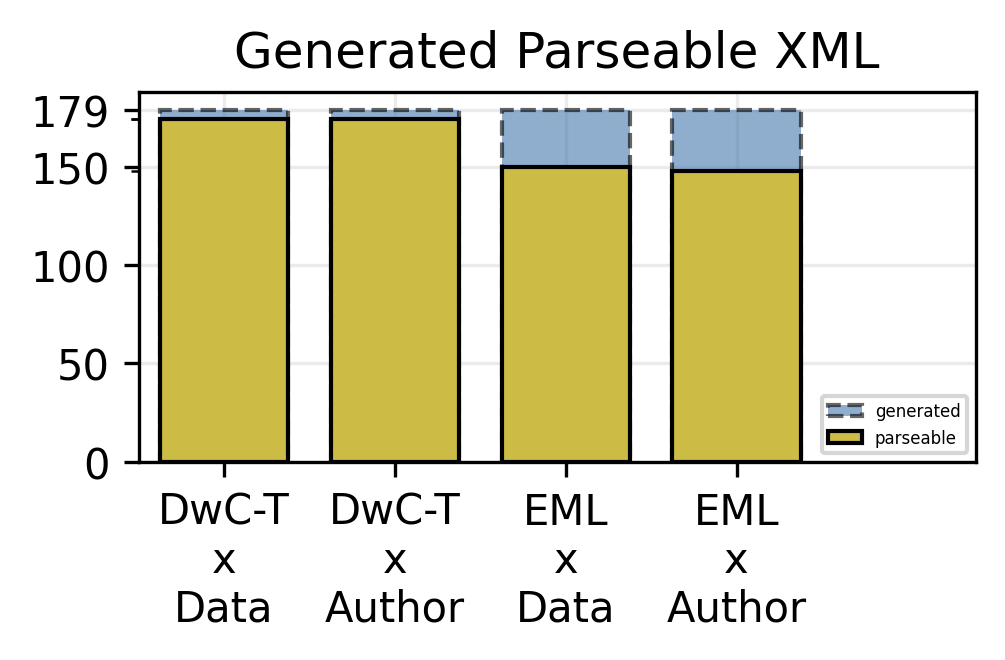

In [33]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array(["\nx\n".join(g.split("~")) for g, rs in result_groups.items()])
experiment_count = np.array([rs.shape[0] for g, rs in result_groups.items()])
ok_experiment_count = np.array([with_ok_constructed_trees(rs).shape[0] for g, rs in result_groups.items()])

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

In [34]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.characteristics"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(get_tree_info)
result_groups[g]["constructed.xml_tree.characteristics"].head()[0]

{'value': {'size': 47,
  'size_with_attributes': 55,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43", "system": "knb", "{http://www.w3.org/XML/1998/namespace}lang": "en"}',
    'attributes_count': 3,
    'has_attributes': True,
    'text': '\n  ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 6,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n    ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'title',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': 'Renato_PhD',
    'has_text': True,
    'path': 'dataset/title'},
   {'tag': 'creator',
    'depth': 2,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{}',
   

In [35]:
for g, rs in result_groups.items():
    result_groups[g]["ground_truth.xml_tree.characteristics"] = rs["ground_truth.xml_tree"].apply(get_tree_info)
result_groups[g]["ground_truth.xml_tree.characteristics"].head()[0]

{'value': {'size': 511,
  'size_with_attributes': 527,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"{http://www.w3.org/2001/XMLSchema-instance}schemaLocation": "https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd", "packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2", "system": "http://gbif.org", "scope": "system", "{http://www.w3.org/XML/1998/namespace}lang": "eng"}',
    'attributes_count': 5,
    'has_attributes': True,
    'text': '\n    ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 26,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n        ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'alternateIdentifier',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_c

### Constructed


In [36]:
cons_tree_info_groups = {}
cons_node_info_groups = {}
for g, rs in result_groups.items():
    cons_tree_info_groups[g] = pd.DataFrame.from_records(
        with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["constructed.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    cons_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["constructed.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [37]:
list([(g,vs["constructed.xml_tree"]) for g,vs in result_groups.items()])

[('DwC-T~Data',
  0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [38]:
for g,rs in cons_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.356322,49.149425,142.752874
std,52.318163,22.960649,68.108990
min,0.000000,12.000000,33.000000
25%,43.250000,33.250000,97.500000
50%,90.500000,45.000000,132.000000
75%,134.750000,60.750000,175.750000
max,178.000000,190.000000,565.000000


DwC-T~Author


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.350575,49.206897,142.885057
std,51.515395,22.552771,67.131124
min,0.000000,12.000000,33.000000
25%,45.250000,34.000000,99.000000
50%,89.500000,45.500000,133.000000
75%,133.750000,61.000000,176.000000
max,178.000000,186.000000,555.000000


EML~Data


,case_id,size,size_with_attributes
count,150.000000,150.000000,150.000000
mean,88.686667,42.460000,50.266667
std,53.070314,9.766145,11.063372
min,0.000000,32.000000,37.000000
25%,42.250000,34.000000,41.000000
50%,88.500000,41.000000,49.000000
75%,134.750000,48.000000,57.000000
max,178.000000,76.000000,86.000000


EML~Author


,case_id,size,size_with_attributes
count,148.000000,148.000000,148.000000
mean,92.864865,40.094595,47.709459
std,50.983477,7.939686,9.134113
min,0.000000,32.000000,37.000000
25%,49.750000,34.000000,41.000000
50%,96.000000,38.000000,46.000000
75%,137.250000,46.000000,54.250000
max,178.000000,65.000000,75.000000


In [39]:
for g,rs in cons_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8552.000000,8552,8552.000000,8552.000000,8552,8552,8552.000000,8552,975,8552,8552
unique,NaN,8,NaN,NaN,2,2928,NaN,2,24,2,332
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7310,NaN,NaN,7844,534,NaN,8018,267,8285,174
mean,88.918732,NaN,1.959308,0.979654,NaN,NaN,1.904467,NaN,NaN,NaN,NaN
std,51.588900,NaN,0.377077,6.206240,NaN,NaN,0.721145,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,43.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,134.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8562.000000,8562,8562.000000,8562.000000,8562,8562,8562.000000,8562,984,8562,8562
unique,NaN,8,NaN,NaN,2,2903,NaN,2,23,2,330
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7308,NaN,NaN,7848,540,NaN,8022,270,8292,174
mean,89.333450,NaN,1.959355,0.979678,NaN,NaN,1.903761,NaN,NaN,NaN,NaN
std,50.609223,NaN,0.377788,6.182620,NaN,NaN,0.720217,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,46.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,6369.000000,6369,6369.000000,6369.000000,6369,6369,6369.000000,6369,6238,6369,6369
unique,NaN,319,NaN,NaN,2,133,NaN,2,1246,2,706
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,697,NaN,NaN,3409,5740,NaN,5740,1258,3433,150
mean,88.133302,NaN,3.396452,0.976448,NaN,NaN,0.183859,NaN,NaN,NaN,NaN
std,53.838807,NaN,1.229222,1.310859,NaN,NaN,0.590399,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,40.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,88.000000,NaN,4.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,135.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,5934.000000,5934,5934.000000,5934.000000,5934,5934,5934.000000,5934,5811,5934,5934
unique,NaN,297,NaN,NaN,2,133,NaN,2,1486,2,558
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,652,NaN,NaN,3194,5327,NaN,5327,1166,3202,148
mean,91.711156,NaN,3.337883,0.975059,NaN,NaN,0.189922,NaN,NaN,NaN,NaN
std,50.854321,NaN,1.219922,1.282741,NaN,NaN,0.601834,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,48.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,92.000000,NaN,3.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,136.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


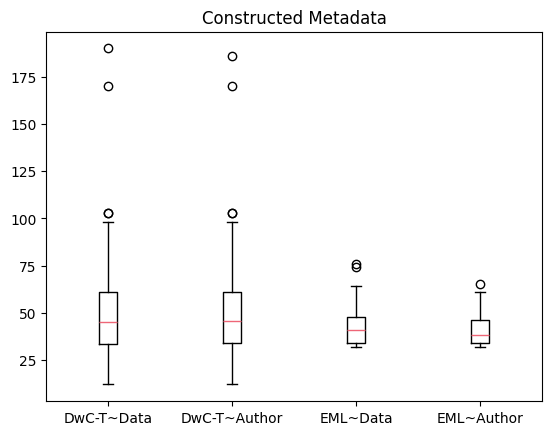

In [40]:
fig,ax = plt.subplots()


ax.set_title("Constructed Metadata")
for i,(g,rs) in enumerate(cons_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

### Ground Truth

In [41]:
gt_tree_info_groups = {}
gt_node_info_groups = {}
for g, rs in result_groups.items():
    gt_tree_info_groups[g] = pd.DataFrame.from_records(
        result_groups[g].apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    gt_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(result_groups[g].apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [42]:
for g,rs in gt_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


DwC-T~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


EML~Data


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


EML~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


In [43]:
for g,rs in gt_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


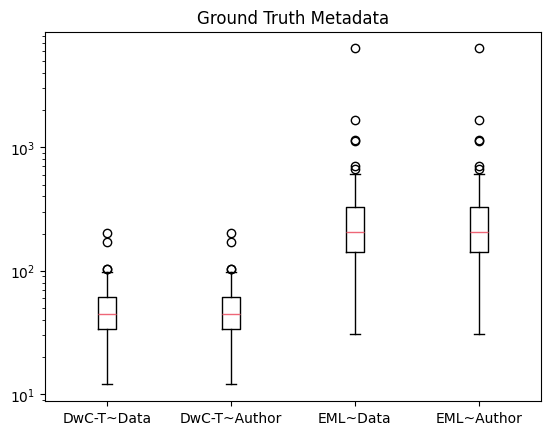

In [44]:
fig,ax = plt.subplots()


ax.set_title("Ground Truth Metadata")
ax.set_yscale("log")
for i,(g,rs) in enumerate(gt_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

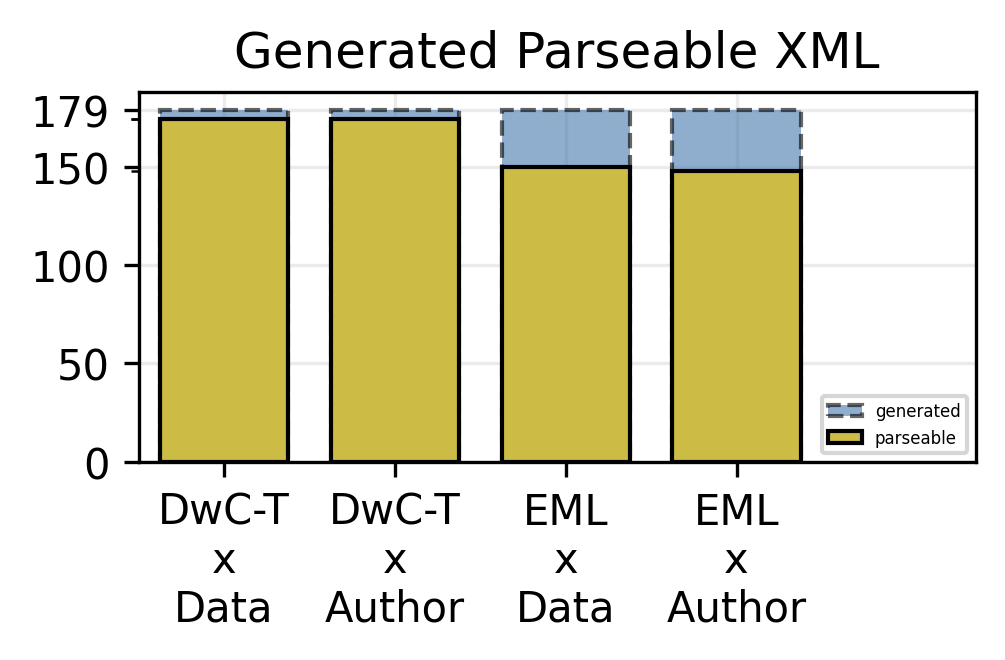

In [45]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array(["\nx\n".join(g.split("~")) for g, rs in result_groups.items()])
experiment_count = np.array([rs.shape[0] for g, rs in result_groups.items()])
ok_experiment_count = np.array([with_ok_constructed_trees(rs).shape[0] for g, rs in result_groups.items()])

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

In [46]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.characteristics"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(get_tree_info)
result_groups[g]["constructed.xml_tree.characteristics"].head()[0]

{'value': {'size': 47,
  'size_with_attributes': 55,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43", "system": "knb", "{http://www.w3.org/XML/1998/namespace}lang": "en"}',
    'attributes_count': 3,
    'has_attributes': True,
    'text': '\n  ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 6,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n    ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'title',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': 'Renato_PhD',
    'has_text': True,
    'path': 'dataset/title'},
   {'tag': 'creator',
    'depth': 2,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{}',
   

In [47]:
for g, rs in result_groups.items():
    result_groups[g]["ground_truth.xml_tree.characteristics"] = rs["ground_truth.xml_tree"].apply(get_tree_info)
result_groups[g]["ground_truth.xml_tree.characteristics"].head()[0]

{'value': {'size': 511,
  'size_with_attributes': 527,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"{http://www.w3.org/2001/XMLSchema-instance}schemaLocation": "https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd", "packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2", "system": "http://gbif.org", "scope": "system", "{http://www.w3.org/XML/1998/namespace}lang": "eng"}',
    'attributes_count': 5,
    'has_attributes': True,
    'text': '\n    ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 26,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n        ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'alternateIdentifier',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_c

## Comparing Structures

In [48]:
cons_group_pairs = {
    "DwC-T": {"Data": result_groups["DwC-T~Data"].copy().set_index("case_id"), "Author": result_groups["DwC-T~Author"].copy().set_index("case_id")},
    "EML": {"Data": result_groups["EML~Data"].copy().set_index("case_id"), "Author": result_groups["EML~Author"].copy().set_index("case_id")},
}

In [49]:
cons_node_group_pairs = {
    "DwC-T": {"Data": cons_node_info_groups["DwC-T~Data"].copy().set_index("case_id"), "Author": cons_node_info_groups["DwC-T~Author"].copy().set_index("case_id")},
    "EML": {"Data": cons_node_info_groups["EML~Data"].copy().set_index("case_id"), "Author": cons_node_info_groups["EML~Author"].copy().set_index("case_id")},
}

In [50]:
for sg, srs in cons_group_pairs.items():
    compared_results = srs["Data"][["constructed.xml_tree.characteristics", "constructed.xml_tree"]].join(
        srs["Author"][["constructed.xml_tree.characteristics", "constructed.xml_tree"]], 
        lsuffix="__data", 
        rsuffix="__author"
    )
    cons_group_pairs[sg]["joined"] = compared_results
    cons_group_pairs[sg]["comparable"] = compared_results.dropna()

(179, 4)
(169, 4)


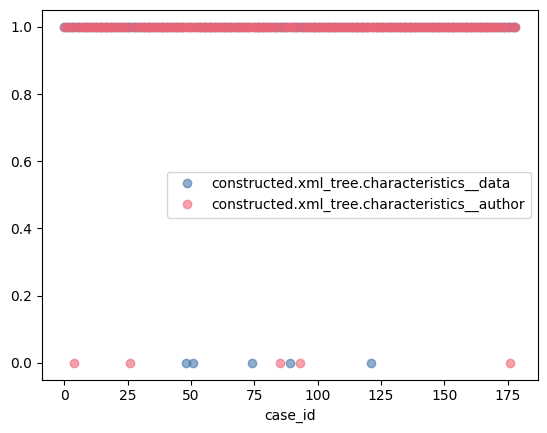

In [51]:
cons_group_pairs["DwC-T"]["joined"][
    ["constructed.xml_tree.characteristics__data", "constructed.xml_tree.characteristics__author"]
].notna().astype(int).plot(lw=0, marker="o", alpha=0.6)
print(cons_group_pairs["DwC-T"]["joined"].shape)
print(cons_group_pairs["DwC-T"]["comparable"].shape)

(179, 4)
(124, 4)


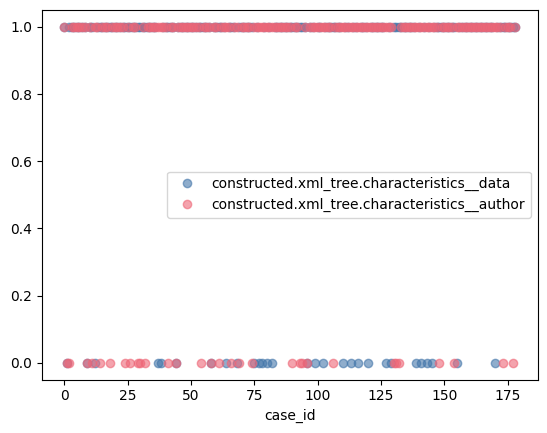

In [52]:
cons_group_pairs["EML"]["joined"][
    ["constructed.xml_tree.characteristics__data", "constructed.xml_tree.characteristics__author"]
].notna().astype(int).plot(lw=0, marker="o", alpha=0.6)
print(cons_group_pairs["EML"]["joined"].shape)
print(cons_group_pairs["EML"]["comparable"].shape)

### Compute JIs

In [53]:
def jaccard_index(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> int:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data))/len(set.union(cons_data,gt_data)))

def intersection_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> int:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data)))

def union_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> int:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.union(cons_data,gt_data)))

def left_minus_set(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> set:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (set.difference(cons_data,gt_data))

def right_minus_set(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> set:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (set.difference(gt_data,cons_data))

In [54]:
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.tag_intersection_size"] = rs["comparable"].apply(
        lambda r: (
            intersection_size("tag", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.tag_union_size"] = rs["comparable"].apply(
        lambda r: (
            union_size("tag", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.tag_jaccard_index"] = rs["comparable"].apply(
        lambda r: (
            jaccard_index("tag", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.data_tree_tags"] = rs["comparable"].apply(
        lambda r: (
            left_minus_set("tag", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.author_tree_tags"] = rs["comparable"].apply(
        lambda r: (
            right_minus_set("tag", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
cons_group_pairs[g]["comparable"]["data_vs_author_tree.tag_jaccard_index"]

case_id
0      0.960000
10     1.000000
100    0.800000
101    0.714286
103    1.000000
         ...   
91     0.774194
92     0.600000
95     1.000000
97     0.666667
98     0.685714
Name: data_vs_author_tree.tag_jaccard_index, Length: 124, dtype: float64

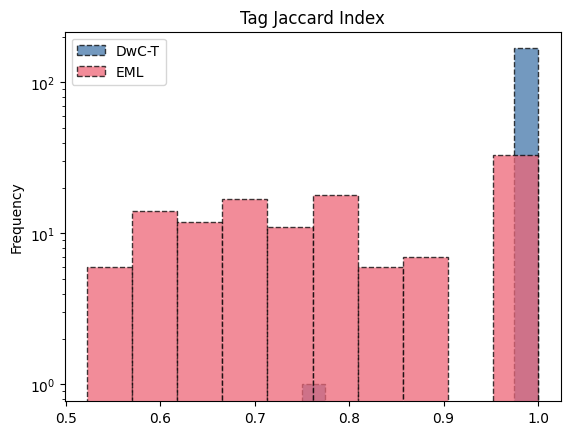

In [55]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.tag_jaccard_index"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Jaccard Index"
    )

<Axes: title={'center': 'Tag Jaccard Index'}, xlabel='case_id'>

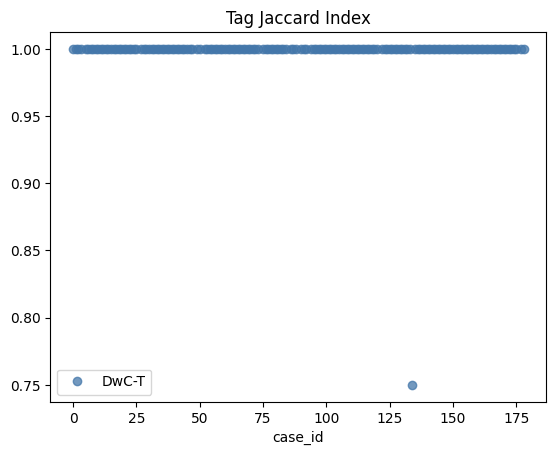

In [56]:
cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.tag_jaccard_index"].plot(
    alpha=0.75, lw=0, marker="o", legend=True, label="DwC-T", title="Tag Jaccard Index"
)

<Axes: title={'center': 'Tag Jaccard Index'}, xlabel='case_id'>

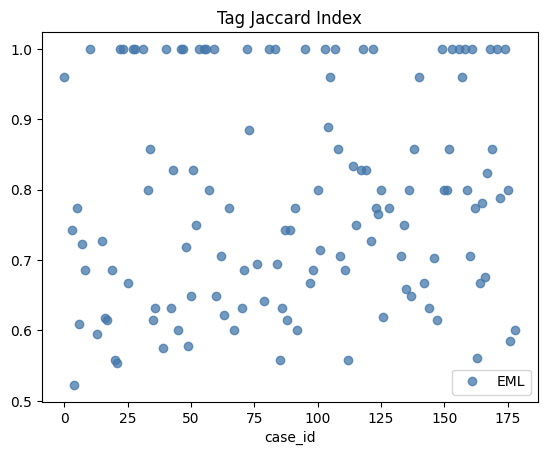

In [57]:
cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.tag_jaccard_index"].plot(
    alpha=0.75, lw=0, marker="o", legend=True, label="EML", title="Tag Jaccard Index"
)

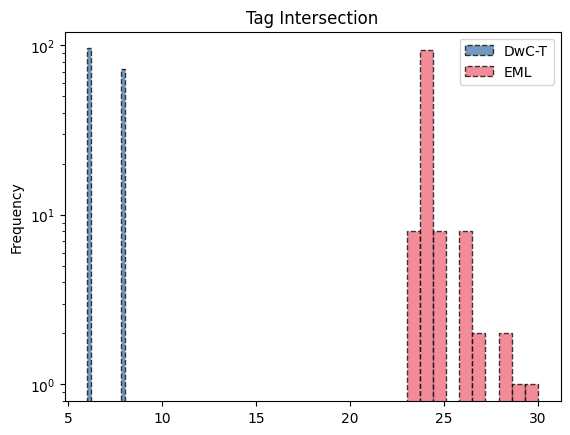

In [58]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.tag_intersection_size"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Intersection"
    )

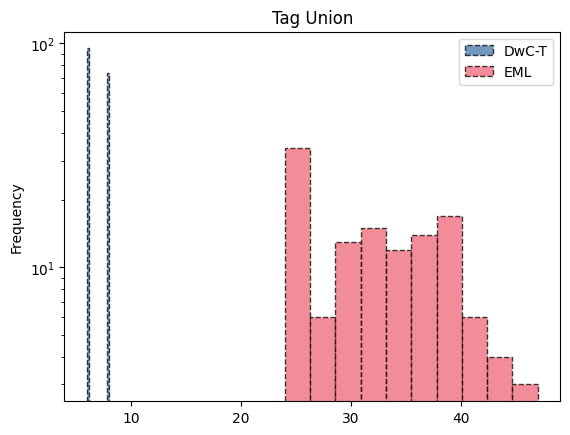

In [59]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.tag_union_size"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Union"
    )

In [60]:
from collections import Counter 

data_tags = Counter(itlx.chain.from_iterable(cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.data_tree_tags"].tolist()))
data_tags = Counter(itlx.chain.from_iterable(cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.author_tree_tags"].tolist()))
pprint(data_tags)
pprint(data_tags)

Counter()
Counter()


In [61]:
from collections import Counter 

data_tags = set(itlx.chain.from_iterable(cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.data_tree_tags"].tolist()))
author_tags = set(itlx.chain.from_iterable(cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.author_tree_tags"].tolist()))
# pprint(data_tags)
# pprint(author_tags)
pprint(author_tags - data_tags)
pprint(data_tags - author_tags)


{'archiveType',
 'associatedMethodCitation',
 'bibliographicCitation',
 'bioinformaticWorkflow',
 'collectionEventType',
 'collectionName',
 'collectionScope',
 'contentSummary',
 'context',
 'continent',
 'controlledVocabularyNotes',
 'curationNote',
 'customProjectContext',
 'dataLanguage',
 'dataMaintenance',
 'dataPackageComposition',
 'dataPackageName',
 'dataProcessingNotes',
 'dataProducts',
 'dataSetURI',
 'dataUpdated',
 'date',
 'datum',
 'distributionType',
 'end',
 'entityName',
 'environmentalVariables',
 'eventCount',
 'eventCoverage',
 'eventDateRange',
 'eventFileSummary',
 'eventSamplingProtocol',
 'extension',
 'field',
 'forward',
 'gapNotes',
 'geographicContext',
 'geographicExample',
 'geographicFocus',
 'georeferenceDatum',
 'georeferencingMethod',
 'hostContext',
 'identificationReference',
 'identificationVerificationStatus',
 'imageRecords',
 'institutionName',
 'introduction',
 'island',
 'keyContextualSignals',
 'keyword',
 'keywordSet',
 'languages',
 'lice

In [62]:
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.path_intersection_size"] = rs["comparable"].apply(
        lambda r: (
            intersection_size("path", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.path_union_size"] = rs["comparable"].apply(
        lambda r: (
            union_size("path", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.path_jaccard_index"] = rs["comparable"].apply(
        lambda r: (
            jaccard_index("path", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.data_tree_paths"] = rs["comparable"].apply(
        lambda r: (
            left_minus_set("path", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.author_tree_paths"] = rs["comparable"].apply(
        lambda r: (
            right_minus_set("path", data_t, author_t)
        ) if (
            (data_t := r["constructed.xml_tree.characteristics__data"]["value"]) and (author_t := r["constructed.xml_tree.characteristics__author"]["value"])
        ) else np.nan, 
        axis=1
    )
cons_group_pairs[g]["comparable"]["data_vs_author_tree.path_jaccard_index"]

case_id
0      0.666667
10     0.490196
100    0.842105
101    0.609375
103    0.833333
         ...   
91     0.600000
92     0.464789
95     1.000000
97     0.500000
98     0.323529
Name: data_vs_author_tree.path_jaccard_index, Length: 124, dtype: float64

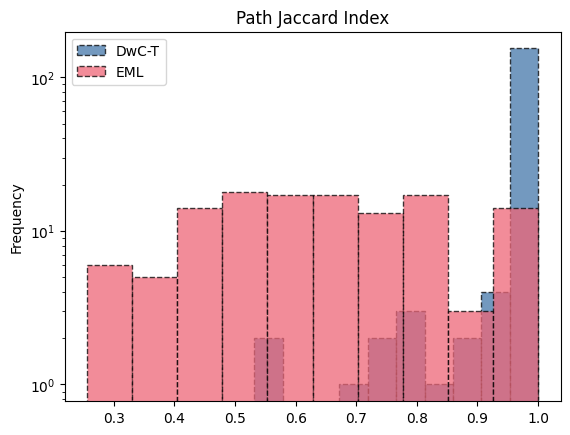

In [63]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.path_jaccard_index"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Jaccard Index"
    )

<Axes: title={'center': 'Path Jaccard Index'}, xlabel='case_id'>

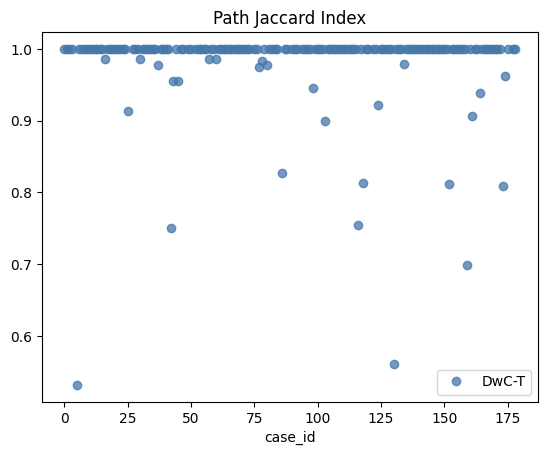

In [64]:
cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.path_jaccard_index"].plot(
    alpha=0.75, lw=0, marker="o", legend=True, label="DwC-T", title="Path Jaccard Index"
)

<Axes: title={'center': 'Path Jaccard Index'}, xlabel='case_id'>

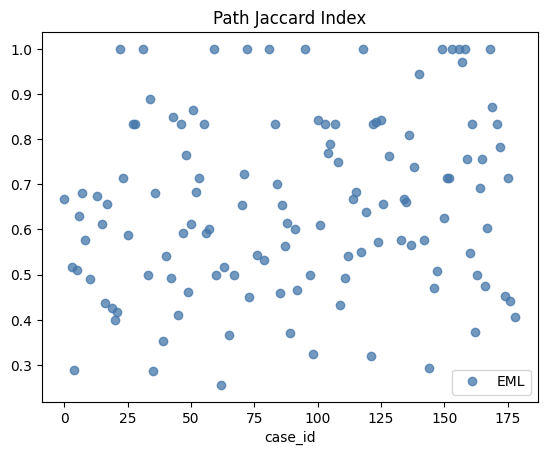

In [65]:
cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.path_jaccard_index"].plot(
    alpha=0.75, lw=0, marker="o", legend=True, label="EML", title="Path Jaccard Index"
)

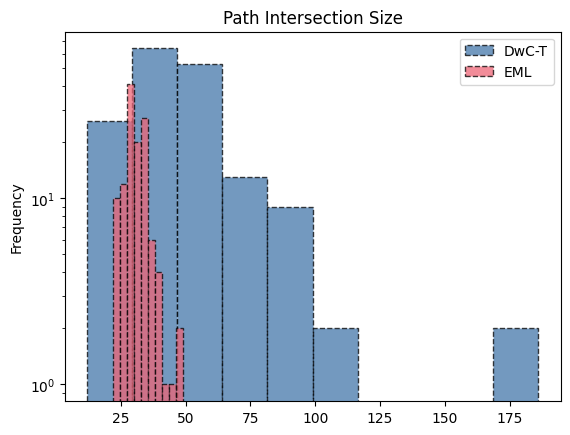

In [66]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.path_intersection_size"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Intersection Size"
    )

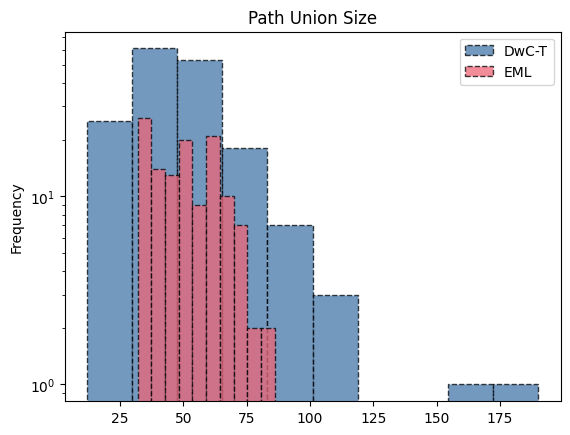

In [67]:
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.path_union_size"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Union Size"
    )

In [68]:
from collections import Counter 

data_paths = Counter(itlx.chain.from_iterable(cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.data_tree_paths"].tolist()))
author_paths = Counter(itlx.chain.from_iterable(cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.author_tree_paths"].tolist()))
pprint(set(data_paths) - set(author_paths))
pprint(set(author_paths) - set(data_paths))

{'{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[20]',
 '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[21]',
 '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[24]',
 '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[25]',
 '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[29]',
 '{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[30]',
 '{http://rs.tdwg.org/dwc/text/}extension',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}coreid',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[10]',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[11]',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[12]',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[13]',
 '{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc

In [69]:
from collections import Counter 

data_paths = Counter(itlx.chain.from_iterable(cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.data_tree_paths"].tolist()))
author_paths = Counter(itlx.chain.from_iterable(cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.author_tree_paths"].tolist()))
pprint(set(data_paths) - set(author_paths))
pprint(set(author_paths) - set(data_paths))

{'additionalMetadata/metadata/citation',
 'additionalMetadata/metadata/citation/para',
 'additionalMetadata/metadata/collectionContext',
 'additionalMetadata/metadata/collectionContext/para',
 'additionalMetadata/metadata/custom',
 'additionalMetadata/metadata/custom/collectionContext',
 'additionalMetadata/metadata/custom/datasetTheme',
 'additionalMetadata/metadata/custom/knownLimitations',
 'additionalMetadata/metadata/custom/provenanceNote',
 'additionalMetadata/metadata/custom/recordBasis',
 'additionalMetadata/metadata/custom/sourceFiles',
 'additionalMetadata/metadata/custom/sourceFiles/delimiter',
 'additionalMetadata/metadata/custom/sourceFiles/fileName',
 'additionalMetadata/metadata/custom/sourceFiles/rowCount',
 'additionalMetadata/metadata/customContext',
 'additionalMetadata/metadata/customContext/dataPackageType',
 'additionalMetadata/metadata/customContext/dataSummary',
 'additionalMetadata/metadata/customContext/dataSummary/basisOfRecord',
 'additionalMetadata/metadata

In [70]:
for g, rs in cons_group_pairs.items():
    print("----")
    print(g)
    print("Tag JI:\t\t", stats.normaltest(rs["comparable"]["data_vs_author_tree.tag_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(rs["comparable"]["data_vs_author_tree.tag_jaccard_index"])))
    print("Path JI:\t", stats.normaltest(rs["comparable"]["data_vs_author_tree.path_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(rs["comparable"]["data_vs_author_tree.path_jaccard_index"])))

----
DwC-T
Tag JI:		 NormaltestResult(statistic=np.float64(370.6315473280134), pvalue=np.float64(3.2989982721971354e-81))
(LogN):		 NormaltestResult(statistic=np.float64(370.63154732800524), pvalue=np.float64(3.29899827221071e-81))
Path JI:	 NormaltestResult(statistic=np.float64(192.46133000860402), pvalue=np.float64(1.6126985621875973e-42))
(LogN):		 NormaltestResult(statistic=np.float64(211.13200973798928), pvalue=np.float64(1.4232022079000645e-46))
----
EML
Tag JI:		 NormaltestResult(statistic=np.float64(63.714497667448995), pvalue=np.float64(1.4607389943707757e-14))
(LogN):		 NormaltestResult(statistic=np.float64(48.0727187585491), pvalue=np.float64(3.640338397449959e-11))
Path JI:	 NormaltestResult(statistic=np.float64(6.756315537159644), pvalue=np.float64(0.03411023583639205))
(LogN):		 NormaltestResult(statistic=np.float64(5.099649953950685), pvalue=np.float64(0.07809533328651688))


### Compute Tree Sim (APTED)

In [71]:
@do_on_value
@do_or_error
def xml_to_apted_tree(tree):
    if hasattr(tree, "getroot"):
        return convert_xml_to_apted(tree.getroot())
    return convert_xml_to_apted(tree)

def convert_xml_to_apted(root):
    tag = root.tag
    
    if root.attrib:
        attr_parts = [f"{{key__{k}:{{hidden_value}}}}" for k, _v in sorted(root.attrib.items())]
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag
    
    apted_children = [convert_xml_to_apted(child) for child in root]    
    return apted.helpers.Tree(node_label, *apted_children)

In [72]:
@do_on_value
def apted_tree_size(tree):
    return _apted_tree_size(tree)

def _apted_tree_size(tree):
    return 1 + sum(_apted_tree_size(child) for child in tree.children)

def normalise_apted_edit_distance(raw_distance, tree1, tree2):
    max_dist = _apted_tree_size(tree1) + _apted_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [73]:
def get_error_breakdown(apted_edit_mapping):
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)

    counts = {f"{key}_count": len(vals) for key, vals in breakdown.items()}
    total = sum(v for _, v in counts.items())
    return {
        **breakdown, 
        **counts,
        "total": total,
        "replacements_count": total - counts["matches_count"],
    }

In [74]:
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["constructed.xml_tree__data.apted_format"] = rs["comparable"]["constructed.xml_tree__data"].apply(xml_to_apted_tree)
    cons_group_pairs[g]["comparable"]["constructed.xml_tree__author.apted_format"] = rs["comparable"]["constructed.xml_tree__author"].apply(xml_to_apted_tree)

In [75]:
%%time
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_distance"] = rs["comparable"].apply(
        lambda x: apted.APTED(x["constructed.xml_tree__data.apted_format"]["value"], x["constructed.xml_tree__author.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_distance()
    )

CPU times: user 1.44 s, sys: 10.7 ms, total: 1.45 s
Wall time: 1.45 s


In [76]:
cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_distance"]

case_id
0       9
10      8
100     7
101    14
103     2
       ..
91     13
92     22
95      0
97     13
98     27
Name: data_vs_author_tree.apted_tree_edit_distance, Length: 124, dtype: int64

In [77]:
%%time
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.normalised"] = rs["comparable"].apply(
        lambda x: normalise_apted_edit_distance(x["data_vs_author_tree.apted_tree_edit_distance"], x["constructed.xml_tree__data.apted_format"]["value"], x["constructed.xml_tree__author.apted_format"]["value"]), 
        axis=1,
    )
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] = 1 - cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.normalised"]

CPU times: user 5.48 ms, sys: 217 μs, total: 5.7 ms
Wall time: 5.62 ms


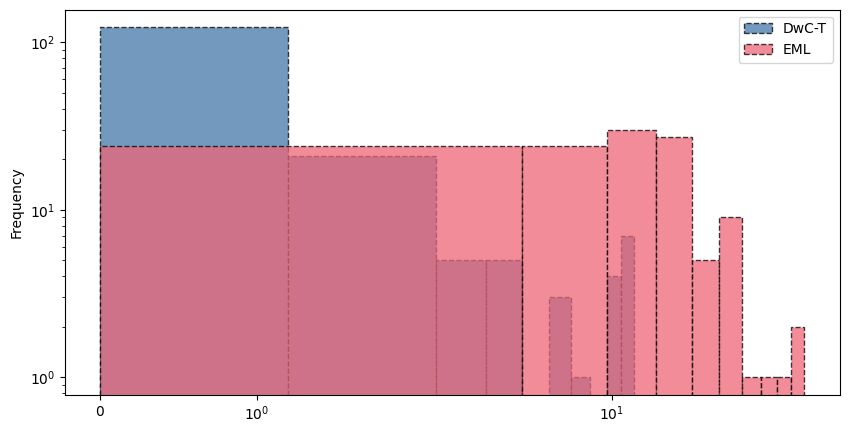

In [78]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_xscale("symlog")
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.apted_tree_edit_distance"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g
    )

plt.show()

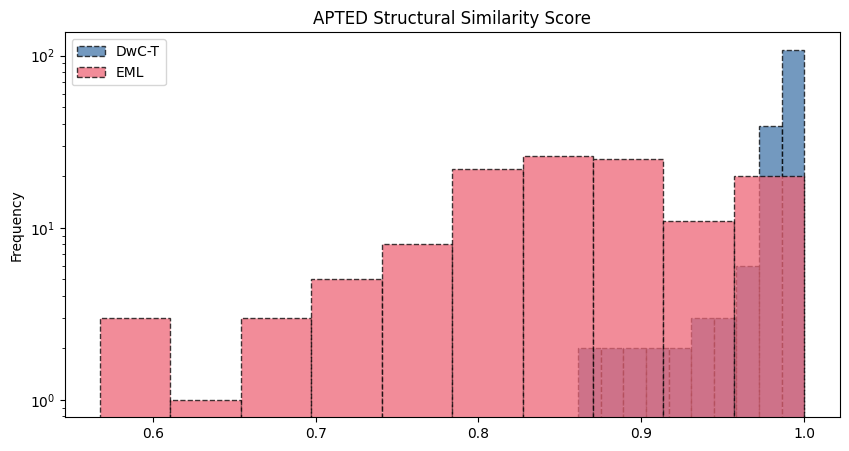

In [79]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_title("APTED Structural Similarity Score")
# ax.set_xscale("symlog")
for g, rs in cons_group_pairs.items():
    rs["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"].plot.hist(
        alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g
    )

plt.show()

In [80]:
for g, rs in cons_group_pairs.items():    
    print("----")
    print(g)
    print("APTED:\t\t", stats.normaltest(rs["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"]))
    print("(LogN):\t\t", stats.normaltest(np.log(rs["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"])))

----
DwC-T
APTED:		 NormaltestResult(statistic=np.float64(115.89114314091452), pvalue=np.float64(6.832159808509148e-26))
(LogN):		 NormaltestResult(statistic=np.float64(120.23483837132997), pvalue=np.float64(7.78639768778292e-27))
----
EML
APTED:		 NormaltestResult(statistic=np.float64(11.687867298155755), pvalue=np.float64(0.002897422735346226))
(LogN):		 NormaltestResult(statistic=np.float64(28.556184141038308), pvalue=np.float64(6.29656080543922e-07))


In [81]:
%%time
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_mapping"] = rs["comparable"].apply(
        lambda x: apted.APTED(x["constructed.xml_tree__data.apted_format"]["value"], x["constructed.xml_tree__author.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_mapping()
    )

CPU times: user 1.73 s, sys: 12.9 ms, total: 1.74 s
Wall time: 1.74 s


In [82]:
for g, rs in cons_group_pairs.items():
    cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_mapping_breakdown"] = rs["comparable"]["data_vs_author_tree.apted_tree_edit_mapping"].apply(get_error_breakdown)
cons_group_pairs[g]["comparable"]["data_vs_author_tree.apted_tree_edit_mapping_breakdown"]

case_id
0                                                                                                                                                                                                                                                                                                                                                                                                                                                             {'deletions': [], 'insertions': ['abstract', 'para', 'methodStep', 'description', 'para', 'personnel', 'role', 'individualName', 'surName'], 'renames': [], 'matches': ['{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}', 'dataset', 'title', 'creator', 'individualName', 'surName', 'userId:{key__directory:{hidden_value}}', 'methods', 'methodStep', 'description', 'para', 'instrumentation', 'qualityControl', 'description', '

In [83]:
tree_edit_breakdown_groups = {}

for g, rs in cons_group_pairs.items():
    tree_edit_breakdown_groups[g] = pd.DataFrame.from_records(rs["comparable"]["data_vs_author_tree.apted_tree_edit_mapping_breakdown"])
    tree_edit_breakdown_groups[g]["case_id"] = rs["comparable"].index
g, tree_edit_breakdown_groups[g].describe()

('EML',
        deletions_count  insertions_count  renames_count  matches_count  \
 count       124.000000        124.000000     124.000000     124.000000   
 mean          5.935484          4.129032       2.580645      33.758065   
 std           8.596409          5.577201       2.834448       3.591704   
 min           0.000000          0.000000       0.000000      29.000000   
 25%           0.000000          0.000000       0.750000      31.000000   
 50%           2.000000          2.000000       1.000000      33.000000   
 75%           8.000000          6.000000       5.000000      34.250000   
 max          44.000000         33.000000      10.000000      49.000000   
 
             total  replacements_count     case_id  
 count  124.000000          124.000000  124.000000  
 mean    46.403226           12.645161   91.322581  
 std     10.152431            9.243933   52.773261  
 min     32.000000            0.000000    0.000000  
 25%     38.000000            6.750000   46.750000

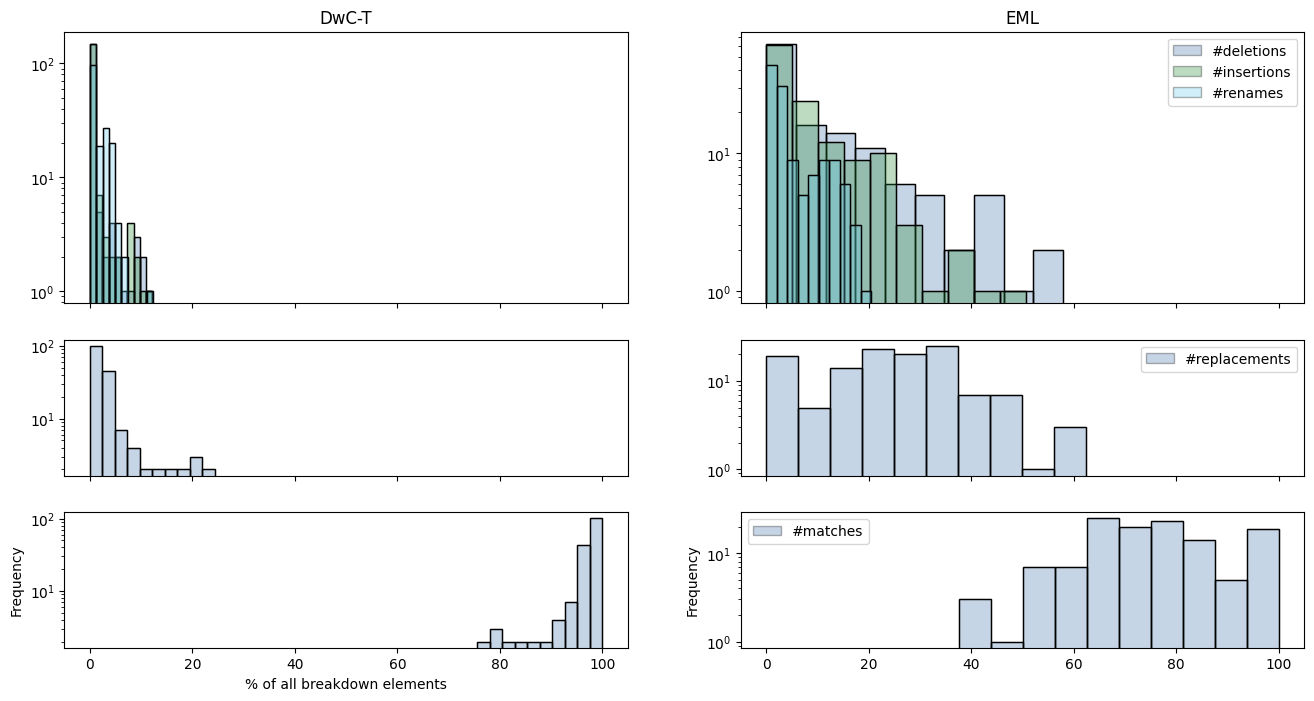

In [84]:
fig, axs = plt.subplots(3, len(tree_edit_breakdown_groups.keys()), figsize=(16,8), sharex=True, height_ratios=(2,1,1), width_ratios=(1,1))

matches_c = "matches_count"
replacements_c = "replacements_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    # matches_c
]

for i, (ax_t, (g, rs)) in enumerate(zip(axs[0], tree_edit_breakdown_groups.items())):
    # ax_t.set_xscale("symlog")
    ax_t.set_title(g)
    for j, (c, ls) in enumerate(zip(columns, ["--", "-.", ":"])):
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, alpha=0.3, edgecolor="k", log=True, ax=ax_t, label=("#" + c.split("_")[0]))
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_t)
    ax_t.legend() if i == 1 else ...
    ax_t.set_ylabel("")

for i, (ax_m, (g, rs)) in enumerate(zip(axs[1], tree_edit_breakdown_groups.items())):
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_m, label="#" + replacements_c.split("_")[0])
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_m)
    ax_m.legend() if i == 1 else ...
    ax_m.set_ylabel("")

for i, (ax_b, (g, rs)) in enumerate(zip(axs[2], tree_edit_breakdown_groups.items())):
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_b, label="#" + matches_c.split("_")[0])
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_b)
    ax_b.set_xlabel("% of all breakdown elements") if i == 0 else ...
    ax_b.legend() if i == 1 else ...

plt.show()

In [85]:
matches_c = "matches_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    matches_c
]

for c in columns:
    for g, rs in tree_edit_breakdown_groups.items():    
        print(f"---- {c} ----")
        print(g)
        print(f"{c}:\t", stats.normaltest(rs[c]))
        print("(LogN1P):\t", stats.normaltest(np.log1p(rs[c])))

---- deletions_count ----
DwC-T
deletions_count:	 NormaltestResult(statistic=np.float64(146.13016155683795), pvalue=np.float64(1.8545502195069612e-32))
(LogN1P):	 NormaltestResult(statistic=np.float64(106.55599754929594), pvalue=np.float64(7.272087994160832e-24))
---- deletions_count ----
EML
deletions_count:	 NormaltestResult(statistic=np.float64(68.74812352122787), pvalue=np.float64(1.1790566083811991e-15))
(LogN1P):	 NormaltestResult(statistic=np.float64(45.97305700206152), pvalue=np.float64(1.0401057897668223e-10))
---- insertions_count ----
DwC-T
insertions_count:	 NormaltestResult(statistic=np.float64(132.6631785849059), pvalue=np.float64(1.5579617623596652e-29))
(LogN1P):	 NormaltestResult(statistic=np.float64(110.69089906078219), pvalue=np.float64(9.19976365876228e-25))
---- insertions_count ----
EML
insertions_count:	 NormaltestResult(statistic=np.float64(68.91292403157867), pvalue=np.float64(1.0857971081190252e-15))
(LogN1P):	 NormaltestResult(statistic=np.float64(70.19679296

### Reporting Pairwise Structural Similiarity

In [86]:
all_tags_groups = {}

for g in cons_node_group_pairs.keys():
    all_tags = sorted(list(set.union(
        set(cons_node_group_pairs[g]["Data"]["tag"].apply(str).unique().tolist()),
        set(cons_node_group_pairs[g]["Author"]["tag"].apply(str).unique().tolist()),
    )))
    all_tags_groups[g] = {
        "values": all_tags, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [87]:
all_paths_groups = {}

for g in cons_node_group_pairs.keys():
    all_paths = sorted(list(set.union(
        set(cons_node_group_pairs[g]["Data"]["path"].apply(str).unique().tolist()),
        set(cons_node_group_pairs[g]["Author"]["path"].apply(str).unique().tolist()),
    )))
    all_paths_groups[g] = {
        "values": all_paths, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [88]:
TOP_K = 20

#### Descriptive Stats

In [89]:
print("Data VS Author: Tree Structural Similarity\n")

for g, rs in cons_group_pairs.items():
    print(f"--- {g} ----")
    display(rs["comparable"][[
        "data_vs_author_tree.apted_tree_edit_distance.sim_score", 
        "data_vs_author_tree.tag_jaccard_index", 
        "data_vs_author_tree.path_jaccard_index"
    ]].describe())

Data VS Author: Tree Structural Similarity

--- DwC-T ----


,data_vs_author_tree.apted_tree_edit_distance.sim_score,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_jaccard_index
count,169.000000,169.000000,169.000000
mean,0.984936,0.998521,0.980995
std,0.026326,0.019231,0.066795
min,0.861111,0.750000,0.531915
25%,0.981707,1.000000,1.000000
50%,1.000000,1.000000,1.000000
75%,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000


--- EML ----


,data_vs_author_tree.apted_tree_edit_distance.sim_score,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_jaccard_index
count,124.000000,124.000000,124.000000
mean,0.857657,0.783817,0.651144
std,0.089885,0.150446,0.193855
min,0.567568,0.522727,0.255814
25%,0.810095,0.656065,0.500000
50%,0.862198,0.774194,0.646072
75%,0.913277,0.960000,0.815476
max,1.000000,1.000000,1.000000


In [90]:
print("Edit Distance Breakdowns\n")

for g, rs in tree_edit_breakdown_groups.items():
    print(f"--- {g} ----")
    display(rs.describe())

Edit Distance Breakdowns

--- DwC-T ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000
mean,0.449704,0.384615,0.710059,48.053254,49.597633,1.544379,89.727811
std,1.375427,1.175139,1.043098,22.565054,23.194139,2.805094,52.022859
min,0.000000,0.000000,0.000000,12.000000,12.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,33.000000,34.000000,0.000000,44.000000
50%,0.000000,0.000000,0.000000,44.000000,47.000000,0.000000,91.000000
75%,0.000000,0.000000,1.000000,58.000000,61.000000,2.000000,135.000000
max,9.000000,5.000000,8.000000,186.000000,190.000000,12.000000,178.000000


--- EML ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.935484,4.129032,2.580645,33.758065,46.403226,12.645161,91.322581
std,8.596409,5.577201,2.834448,3.591704,10.152431,9.243933,52.773261
min,0.000000,0.000000,0.000000,29.000000,32.000000,0.000000,0.000000
25%,0.000000,0.000000,0.750000,31.000000,38.000000,6.750000,46.750000
50%,2.000000,2.000000,1.000000,33.000000,46.000000,12.000000,91.500000
75%,8.000000,6.000000,5.000000,34.250000,52.250000,17.000000,137.250000
max,44.000000,33.000000,10.000000,49.000000,77.000000,48.000000,178.000000


### DwC-T Insights

In [91]:
exactly_1_df = cons_group_pairs["DwC-T"]["comparable"][cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] == 1]
less_then_09_df = cons_group_pairs["DwC-T"]["comparable"][cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] < 0.9]
between_09_1_df = cons_group_pairs["DwC-T"]["comparable"][
    (cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] < 1)
    * 
    (cons_group_pairs["DwC-T"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] >= 0.9)
]

less_then_09_df_edit_breakdown = pd.DataFrame.from_records(less_then_09_df["data_vs_author_tree.apted_tree_edit_mapping_breakdown"].tolist())
between_09_1_df_edit_breakdown = pd.DataFrame.from_records(between_09_1_df["data_vs_author_tree.apted_tree_edit_mapping_breakdown"].tolist())


print(exactly_1_df.index.sort_values())
print(less_then_09_df.index.sort_values())
print(between_09_1_df.index.sort_values())

display(exactly_1_df.describe())
display(less_then_09_df.describe())
display(between_09_1_df.describe())

display(less_then_09_df_edit_breakdown.describe())
display(between_09_1_df_edit_breakdown.describe())

Index([  0,   1,   2,   7,  12,  14,  15,  17,  19,  20,  21,  23,  24,  27,
        29,  32,  38,  40,  49,  50,  52,  53,  54,  58,  59,  61,  62,  64,
        65,  66,  68,  71,  76,  79,  84,  87,  91,  94,  96,  99, 101, 104,
       105, 106, 107, 108, 110, 111, 112, 117, 122, 123, 126, 128, 129, 131,
       133, 135, 136, 137, 138, 140, 141, 143, 144, 145, 146, 147, 148, 149,
       150, 151, 153, 154, 156, 160, 162, 165, 167, 168, 169, 171, 172, 177,
       178],
      dtype='int64', name='case_id')
Index([5, 86, 116, 118, 130, 152], dtype='int64', name='case_id')
Index([  3,   6,   8,   9,  10,  11,  13,  16,  18,  22,  25,  28,  30,  31,
        33,  34,  35,  36,  37,  39,  41,  42,  43,  44,  45,  46,  47,  55,
        56,  57,  60,  63,  67,  69,  70,  72,  73,  75,  77,  78,  80,  81,
        82,  83,  88,  90,  92,  95,  97,  98, 100, 102, 103, 109, 113, 114,
       115, 119, 120, 124, 125, 127, 132, 134, 139, 142, 155, 157, 158, 159,
       161, 163, 164, 166, 170, 173, 

,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,85.000000,85.000000,85.0,85.000000,85.000000,85.0,85.0,85.0,85.0
mean,6.564706,6.564706,1.0,46.094118,46.094118,1.0,0.0,0.0,1.0
std,0.905631,0.905631,0.0,17.870316,17.870316,0.0,0.0,0.0,0.0
min,6.000000,6.000000,1.0,12.000000,12.000000,1.0,0.0,0.0,1.0
25%,6.000000,6.000000,1.0,33.000000,33.000000,1.0,0.0,0.0,1.0
50%,6.000000,6.000000,1.0,44.000000,44.000000,1.0,0.0,0.0,1.0
75%,8.000000,8.000000,1.0,55.000000,55.000000,1.0,0.0,0.0,1.0
max,8.000000,8.000000,1.0,103.000000,103.000000,1.0,0.0,0.0,1.0


,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,6.0,6.0,6.0,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,8.0,8.0,1.0,37.333333,52.500000,0.716394,10.500000,0.118064,0.881936
std,0.0,0.0,0.0,6.623192,7.007139,0.134361,0.547723,0.012986,0.012986
min,8.0,8.0,1.0,25.000000,47.000000,0.531915,10.000000,0.105263,0.861111
25%,8.0,8.0,1.0,37.000000,48.250000,0.609230,10.000000,0.108743,0.875334
50%,8.0,8.0,1.0,38.000000,50.500000,0.783211,10.500000,0.114763,0.885237
75%,8.0,8.0,1.0,42.000000,52.750000,0.812205,11.000000,0.124666,0.891257
max,8.0,8.0,1.0,43.000000,66.000000,0.826923,11.000000,0.138889,0.894737


,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000
mean,7.102564,7.128205,0.996795,52.179487,53.564103,0.980638,2.538462,0.023556,0.976444
std,1.001165,0.998167,0.028307,27.342343,28.273520,0.052035,2.695317,0.018733,0.018733
min,6.000000,6.000000,0.750000,21.000000,21.000000,0.698630,1.000000,0.005882,0.904762
25%,6.000000,6.000000,1.000000,35.250000,35.250000,0.985706,1.000000,0.013607,0.976876
50%,8.000000,8.000000,1.000000,48.500000,49.000000,1.000000,2.000000,0.016954,0.983046
75%,8.000000,8.000000,1.000000,63.750000,67.000000,1.000000,2.000000,0.023124,0.986393
max,8.000000,8.000000,1.000000,186.000000,190.000000,1.000000,12.000000,0.095238,0.994118


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,4.833333,4.666667,1.000000,39.166667,49.666667,10.500000
std,0.408248,0.516398,0.632456,4.956477,5.240865,0.547723
min,4.000000,4.000000,0.000000,31.000000,41.000000,10.000000
25%,5.000000,4.250000,1.000000,37.250000,48.000000,10.000000
50%,5.000000,5.000000,1.000000,40.000000,50.000000,10.500000
75%,5.000000,5.000000,1.000000,42.000000,52.750000,11.000000
max,5.000000,5.000000,2.000000,45.000000,56.000000,11.000000


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count
count,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000
mean,0.602564,0.474359,1.461538,50.871795,53.410256,2.538462
std,1.540279,1.181287,1.101266,27.249382,28.201242,2.695317
min,0.000000,0.000000,0.000000,20.000000,21.000000,1.000000
25%,0.000000,0.000000,1.000000,34.250000,35.250000,1.000000
50%,0.000000,0.000000,1.000000,46.500000,49.000000,2.000000
75%,0.000000,0.000000,2.000000,61.500000,66.750000,2.000000
max,9.000000,5.000000,8.000000,186.000000,190.000000,12.000000


<Axes: ylabel='Frequency'>

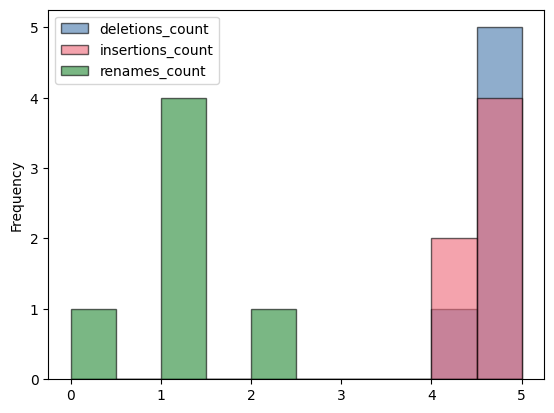

In [92]:
less_then_09_df_edit_breakdown[
        ["deletions_count", "insertions_count", "renames_count"]
].plot.hist(alpha=0.6, ls="-", edgecolor="k")

<Axes: ylabel='Frequency'>

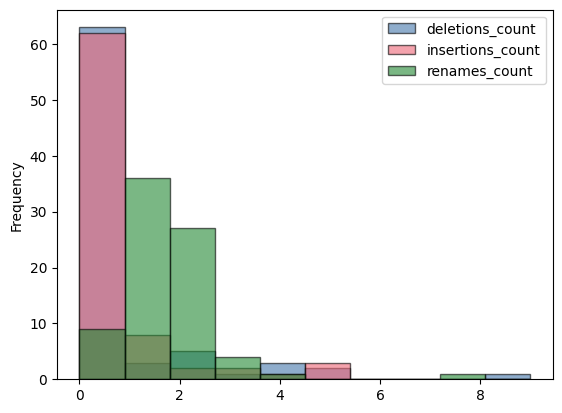

In [93]:
between_09_1_df_edit_breakdown[
        ["deletions_count", "insertions_count", "renames_count"]
].plot.hist(alpha=0.6, ls="-", edgecolor="k")

In [94]:
between_09_1_df_edit_breakdown[between_09_1_df_edit_breakdown[["deletions", "insertions"]] != [[], []]][["deletions", "insertions"]].dropna()

,deletions,insertions
3,"[{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}]"
11,"[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]"
22,"[{http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]"
26,"[{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}]"
29,"[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.

In [95]:
between_09_1_df_edit_breakdown[between_09_1_df_edit_breakdown["renames_count"] != 0][["renames"]].dropna()

,renames
0,"[({http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
1,"[({http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
2,"[({http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}), ({http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
3,"[({http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}), ({http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
4,"[({http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__delimitedBy:{hidden_value}}:{key__index:{hidden_value}}:{key__term:{hidden_value}}), ({http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__delimitedBy:{hidden_value}}:{key__index:{hidden_value}}:{key__term:{hidden_value}})]"
...,...
72,"[({http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
73,"[({http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}})]"
74,"[({http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hid

In [96]:
less_then_09_df_edit_breakdown[less_then_09_df_edit_breakdown[["deletions", "insertions"]] != [[], []]][["deletions", "insertions"]].dropna()

,deletions,insertions
0,"[{http://rs.tdwg.org/dwc/text/}extension:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]"
1,"[{http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}core:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]"
2,"[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]"
3,"[{http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}]","[{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}files, {http://rs.tdwg.org/dwc/text/}location, {http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLi

### EML Insights

In [97]:
exactly_1_df = cons_group_pairs["EML"]["comparable"][cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] == 1]
less_then_09_df = cons_group_pairs["EML"]["comparable"][cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] < 0.9]
between_09_1_df = cons_group_pairs["EML"]["comparable"][
    (cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] < 1)
    * 
    (cons_group_pairs["EML"]["comparable"]["data_vs_author_tree.apted_tree_edit_distance.sim_score"] >= 0.9)
]

less_then_09_df_edit_breakdown = pd.DataFrame.from_records(less_then_09_df["data_vs_author_tree.apted_tree_edit_mapping_breakdown"].tolist())
between_09_1_df_edit_breakdown = pd.DataFrame.from_records(between_09_1_df["data_vs_author_tree.apted_tree_edit_mapping_breakdown"].tolist())


print(exactly_1_df.index.sort_values())
print(less_then_09_df.index.sort_values())
print(between_09_1_df.index.sort_values())

display(exactly_1_df.describe())
display(less_then_09_df.describe())
display(between_09_1_df.describe())

display(less_then_09_df_edit_breakdown.describe())
display(between_09_1_df_edit_breakdown.describe())

Index([22, 31, 72, 95, 118, 149, 158, 168], dtype='int64', name='case_id')
Index([  0,   3,   4,   5,   6,   7,   8,  10,  13,  15,  16,  17,  19,  20,
        21,  25,  33,  35,  36,  39,  40,  42,  45,  48,  49,  50,  51,  52,
        57,  60,  62,  63,  65,  67,  70,  71,  76,  79,  84,  85,  86,  87,
        88,  89,  91,  92,  97,  98, 101, 109, 111, 112, 114, 115, 117, 119,
       121, 124, 125, 126, 128, 133, 134, 135, 136, 137, 138, 142, 144, 146,
       147, 150, 151, 152, 159, 160, 162, 163, 164, 165, 166, 169, 174, 175,
       176, 178],
      dtype='int64', name='case_id')
Index([ 23,  27,  28,  34,  43,  46,  47,  53,  55,  56,  59,  73,  81,  83,
       100, 103, 104, 105, 107, 108, 122, 123, 140, 153, 156, 157, 161, 167,
       171, 172],
      dtype='int64', name='case_id')


,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,8.0,8.0,8.0,8.000000,8.000000,8.0,8.0,8.0,8.0
mean,24.0,24.0,1.0,33.000000,33.000000,1.0,0.0,0.0,1.0
std,0.0,0.0,0.0,1.069045,1.069045,0.0,0.0,0.0,0.0
min,24.0,24.0,1.0,32.000000,32.000000,1.0,0.0,0.0,1.0
25%,24.0,24.0,1.0,32.000000,32.000000,1.0,0.0,0.0,1.0
50%,24.0,24.0,1.0,33.000000,33.000000,1.0,0.0,0.0,1.0
75%,24.0,24.0,1.0,34.000000,34.000000,1.0,0.0,0.0,1.0
max,24.0,24.0,1.0,34.000000,34.000000,1.0,0.0,0.0,1.0


,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000
mean,24.418605,35.244186,0.707121,31.197674,57.627907,0.561867,16.790698,0.185246,0.814754
std,1.202596,5.199403,0.104827,5.302208,10.778024,0.140267,7.975132,0.071108,0.071108
min,23.000000,24.000000,0.522727,22.000000,37.000000,0.255814,7.000000,0.101449,0.567568
25%,24.000000,31.000000,0.624111,29.000000,50.000000,0.466239,11.250000,0.135332,0.788715
50%,24.000000,36.000000,0.694444,30.000000,58.000000,0.564269,15.000000,0.170455,0.829545
75%,24.000000,39.000000,0.774194,34.000000,64.000000,0.666667,19.000000,0.211285,0.864668
max,30.000000,47.000000,1.000000,49.000000,86.000000,0.871795,48.000000,0.432432,0.898551


,data_vs_author_tree.tag_intersection_size,data_vs_author_tree.tag_union_size,data_vs_author_tree.tag_jaccard_index,data_vs_author_tree.path_intersection_size,data_vs_author_tree.path_union_size,data_vs_author_tree.path_jaccard_index,data_vs_author_tree.apted_tree_edit_distance,data_vs_author_tree.apted_tree_edit_distance.normalised,data_vs_author_tree.apted_tree_edit_distance.sim_score
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,24.166667,25.766667,0.946033,30.966667,38.800000,0.814045,4.133333,0.057313,0.942687
std,0.833908,2.908766,0.078949,3.189242,6.059475,0.130624,2.445733,0.030325,0.030325
min,23.000000,24.000000,0.774194,23.000000,32.000000,0.450980,1.000000,0.015625,0.900000
25%,24.000000,24.000000,0.885684,30.000000,36.000000,0.772575,2.000000,0.030303,0.914055
50%,24.000000,24.000000,1.000000,30.000000,36.000000,0.833333,3.000000,0.045455,0.954545
75%,24.000000,26.750000,1.000000,32.000000,41.500000,0.848026,6.000000,0.085945,0.969697
max,28.000000,34.000000,1.000000,41.000000,58.000000,1.000000,9.000000,0.100000,0.984375


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count
count,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000
mean,8.000000,5.383721,3.406977,34.313953,51.104651,16.790698
std,9.551101,6.164736,3.019068,3.926566,8.288942,7.975132
min,0.000000,0.000000,0.000000,29.000000,37.000000,7.000000
25%,1.000000,0.000000,1.000000,32.000000,46.000000,11.250000
50%,5.500000,3.500000,2.000000,33.000000,50.000000,15.000000
75%,11.750000,9.000000,6.000000,35.750000,56.750000,19.000000
max,44.000000,33.000000,10.000000,49.000000,77.000000,48.000000


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,1.600000,1.633333,0.900000,32.366667,36.500000,4.133333
std,2.061135,2.173244,0.758856,2.484203,4.352962,2.445733
min,0.000000,0.000000,0.000000,30.000000,32.000000,1.000000
25%,0.000000,0.000000,0.250000,31.000000,34.000000,2.000000
50%,0.500000,0.000000,1.000000,32.000000,35.000000,3.000000
75%,2.000000,2.000000,1.000000,32.750000,38.000000,6.000000
max,6.000000,6.000000,3.000000,41.000000,49.000000,9.000000


<Axes: ylabel='Frequency'>

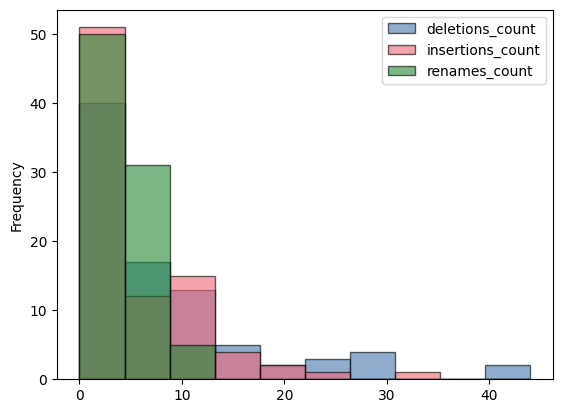

In [98]:
less_then_09_df_edit_breakdown[
        ["deletions_count", "insertions_count", "renames_count"]
].plot.hist(alpha=0.6, ls="-", edgecolor="k")

<Axes: ylabel='Frequency'>

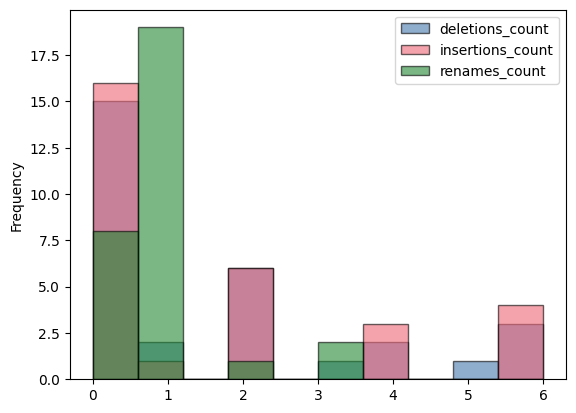

In [99]:
between_09_1_df_edit_breakdown[
        ["deletions_count", "insertions_count", "renames_count"]
].plot.hist(alpha=0.6, ls="-", edgecolor="k")

In [100]:
between_09_1_df_edit_breakdown[between_09_1_df_edit_breakdown[["deletions", "insertions"]] != [[], []]][["deletions", "insertions"]].dropna()

,deletions,insertions
7,"[customMetadata, datasetSummary, provenanceNote, georeferenceContext, taxonSummary, recordCount]","[abstract, para]"
13,[collectionCode],"[methodStep, description, para, datasetProvenance]"
15,"[contextNotes, note, note]",[provenanceNote]


In [101]:
between_09_1_df_edit_breakdown[between_09_1_df_edit_breakdown["renames_count"] != 0][["renames"]].dropna()

,renames
0,"[(additionalMetadata:{key__id:{hidden_value}}, additionalMetadata)]"
2,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}})]"
3,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}})]"
6,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
7,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
8,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
9,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
10,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
11,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}})]"
13,"[({https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}, {https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}), (sourceArchive, sourceSystem), (sourceInstitution, basisOfRecord)]"


In [102]:
less_then_09_df_edit_breakdown[less_then_09_df_edit_breakdown[["deletions", "insertions"]] != [[], []]][["deletions", "insertions"]].dropna()

,deletions,insertions
2,[maintenanceDescription],"[methodStep, description, para, personnel, role, individualName, surName, notes, collectionScope, island]"
3,"[abstract, para, sampling, samplingDescription, para, descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}, descriptorValue]","[provenance, notes, identificationVerificationStatus, georeferencingMethod, sourceType]"
5,"[methods, sampling, samplingDescription, para, studyExtent, description, para, qualityControl, description, para, methodStep, description, para, methodStep, instrumentation, description, para, organizationName, givenName, designDescription, para, organizationName, givenName, organizationName, givenName, maintenanceNote, para, processingHints, para, provenance]","[methods, methodStep, description, para, methodStep, instrumentation, description, para, locality, environmentalVariables, samplingProtocol, taxaObserved, occurrenceCount]"
6,[institutionCode],"[personnel, role, individualName, surName, provenanceNote]"
11,"[datasetTheme, file, file, file, note, gap, gap, gap]","[descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}, descriptorValue]"
13,[collectionContext],"[observedContext, localityContext, hostContext]"
15,"[taxonomicNotes, coordinates]","[date, provenance, spatialCoverage]"
17,[dataset],"[{https://eml.ecoinformatics.org/eml-2.2.0}eml:{key__packageId:{hidden_value}}:{key__system:{hidden_value}}:{key__{http://www.w3.org/XML/1998/namespace}lang:{hidden_value}}, abstract, para, customExtensions, recordBasis]"
18,"[datasetProvenance, notes]","[observedContext, taxonomicScope, datasetType, sourceFile]"
20,"[describes, sourceFiles, note]","[descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}, descriptorValue]"
